# Imputation Results (Member 2)

This notebook walks through the imputation part of the project from start to finish:

1. **Before**: what one corrupted dataset looks like
2. **Live demo**: filling it with each method and comparing guesses with the true values
3. **Checks**: no gaps left, no observed value changed, results reproducible
4. **Results**: the method comparison across all 300 imputed datasets
5. **Figures**: error and spread vs missingness level
6. **Takeaways**

Run it with *Run All*. It takes about a minute. Random forest is not re-run live (about 1 minute per dataset); its saved files are loaded instead.

In [1]:
import sys, time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.handoff import load_condition
from src.imputation import impute, load_config, score_imputation

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
config = load_config(str(PROJECT_ROOT / "config.yaml"))
COLS = config["missingness_columns"]
METHODS = config["imputation_methods"]
print("Methods:", METHODS)
print("Columns with missing values:", COLS)

Methods: ['mean', 'knn', 'regression', 'random_forest']
Columns with missing values: ['sqft_living', 'grade', 'bathrooms', 'yr_built']


## 1. Before: one corrupted dataset

We use **MAR, 30% missingness, repeat 0** as the example. Member 1 removed values from 4 columns, and houses further east were more likely to lose values.

In [2]:
data = load_condition("MAR", 0.30, 0)
corrupted, truth, mask = data["corrupted"], data["truth"], data["mask"]
train_idx, test_idx = data["train_idx"], data["test_idx"]

print(f"Rows: {len(corrupted):,}  (train {len(train_idx):,} / test {len(test_idx):,})")
print("\nMissing values per column:")
print(corrupted[COLS].isna().sum().to_string())

example_rows = corrupted.index[corrupted[COLS].isna().sum(axis=1) >= 2][:5]
corrupted.loc[example_rows, ["price", "bedrooms"] + COLS]

Rows: 21,436  (train 17,148 / test 4,288)

Missing values per column:
sqft_living    6430
grade          6430
bathrooms      6430
yr_built       6430


,price,bedrooms,sqft_living,grade,bathrooms,yr_built
row_index,,,,,,
0,437500.0,3,NaN,NaN,2.25,NaN
2,675000.0,5,NaN,NaN,2.50,NaN
3,555000.0,4,NaN,NaN,NaN,NaN
7,550000.0,4,NaN,7.0,NaN,1976.0
10,285000.0,4,NaN,NaN,2.50,1987.0


## 2. Live demo: fill the gaps

Every method is **fitted on the training rows only** and **never sees `price` or `log_price`**. Mean, KNN and regression run live here; random forest is loaded from its saved file.

In [3]:
filled = {}
for method in ["mean", "knn", "regression"]:
    start = time.perf_counter()
    filled[method] = impute(corrupted, train_idx, method, config)
    print(f"{method:<13} filled in {time.perf_counter() - start:5.1f} s")

filled["random_forest"] = pd.read_csv(
    PROJECT_ROOT / "data/imputed/random_forest/MAR/rate_30/rep_0.csv.gz", index_col="row_index"
)
print("random_forest loaded from data/imputed/")

mean          filled in   0.1 s


knn           filled in  43.7 s


regression    filled in   1.1 s
random_forest loaded from data/imputed/


### Guesses vs true values for the same houses

`sqft_living` was removed for these houses. Each column shows one method's guess; `TRUE` is the real value, which the methods never saw.

In [4]:
rows = corrupted.index[corrupted["sqft_living"].isna()][:8]
compare = pd.DataFrame({"TRUE": truth.loc[rows, "sqft_living"]})
for method in METHODS:
    compare[method] = filled[method].loc[rows, "sqft_living"].round(0)
compare

,TRUE,mean,knn,regression,random_forest
row_index,,,,,
0,1970,2006.0,2330.0,2214.0,2172.0
2,2820,2006.0,3862.0,2990.0,2881.0
3,3310,2006.0,2520.0,2463.0,2503.0
7,1940,2006.0,2486.0,2051.0,2201.0
10,2200,2006.0,2356.0,2511.0,2251.0
15,1320,2006.0,1356.0,2176.0,1424.0
18,1580,2006.0,1196.0,1499.0,1121.0
19,2820,2006.0,2644.0,2347.0,2716.0


### Error on this dataset

**NRMSE** = error divided by the column's natural spread. **1.0 means no better than guessing the average**; lower is better.

In [5]:
nrmse = pd.DataFrame({
    method: score_imputation(filled[method], truth, mask, train_idx, test_idx)
            .query("split == 'all'").set_index("column")["nrmse"]
    for method in METHODS
}).round(2)
nrmse.loc["AVERAGE"] = nrmse.mean().round(2)
nrmse

,mean,knn,regression,random_forest
column,,,,
sqft_living,1.10,0.61,0.52,0.50
grade,1.07,0.65,0.62,0.57
bathrooms,0.99,0.63,0.59,0.55
yr_built,0.97,0.47,0.61,0.41
AVERAGE,1.03,0.59,0.58,0.51


## 3. Checks

Each imputed file must:
- fill every gap,
- leave every observed value exactly as it was,
- keep the same rows and columns.

It must also be **reproducible**: running it again gives exactly the same file.

In [6]:
observed = corrupted.notna().to_numpy()
checks = []
for method in METHODS:
    f = filled[method]
    checks.append({
        "method": method,
        "gaps left": int(f.isna().sum().sum()),
        "observed values changed": int((f.to_numpy()[observed] != corrupted.to_numpy()[observed]).sum()),
        "same rows & columns": f.index.equals(corrupted.index) and list(f.columns) == list(corrupted.columns),
    })
pd.DataFrame(checks)

,method,gaps left,observed values changed,same rows & columns
0,mean,0,0,True
1,knn,0,0,True
2,regression,0,0,True
3,random_forest,0,0,True


In [7]:
saved = pd.read_csv(PROJECT_ROOT / "data/imputed/regression/MAR/rate_30/rep_0.csv.gz", index_col="row_index")
print("Live regression run identical to saved file:", np.allclose(saved.to_numpy(), filled["regression"].to_numpy()))

Live regression run identical to saved file: True


### No-leakage check: does the price affect the fills?

If we shuffle the price column randomly and impute again, the filled values should not change at all. That shows the imputer never uses the target.

In [8]:
shuffled = corrupted.copy()
shuffled["price"] = shuffled["price"].sample(frac=1, random_state=1).to_numpy()
shuffled["log_price"] = np.log(shuffled["price"])
again = impute(shuffled, train_idx, "regression", config)
print("Fills unchanged after shuffling price:", again[COLS].equals(filled["regression"][COLS]))

Fills unchanged after shuffling price: True


## 4. Results across all 300 imputed datasets

Averaged over the 4 columns, 5 missingness levels and 5 repeats (**Table 3**).
- **NRMSE**: error (lower is better; 1 = as bad as guessing the average)
- **sd_ratio**: spread kept (1 = natural spread; below 1 = guesses squeezed toward the middle)

In [9]:
table3 = pd.read_csv(PROJECT_ROOT / "results/tables/imputation_method_comparison.csv")
view = table3.pivot(index="method", columns="mechanism", values="nrmse_mean")[["MCAR", "MAR", "MNAR"]]
view.columns = [f"NRMSE {c}" for c in view.columns]
spread = table3.pivot(index="method", columns="mechanism", values="sd_ratio_mean")[["MCAR", "MAR", "MNAR"]]
spread.columns = [f"spread {c}" for c in spread.columns]
secs = table3.groupby("method")["seconds_per_run"].mean().rename("seconds/run")
(view.join(spread).join(secs)).loc[METHODS].round(2)

,NRMSE MCAR,NRMSE MAR,NRMSE MNAR,spread MCAR,spread MAR,spread MNAR,seconds/run
method,,,,,,,
mean,1.00,1.03,1.46,0.00,0.00,0.00,0.03
knn,0.56,0.58,0.83,0.84,0.82,0.70,18.86
regression,0.59,0.58,0.84,0.84,0.83,0.69,0.56
random_forest,0.49,0.51,0.72,0.89,0.87,0.74,58.91


### Are guesses too high or too low? (bias at 30% missingness)

Bias = average of (guess − true value) for `sqft_living`, in square feet. Negative means the guesses are too low.

In [10]:
summary = pd.read_csv(PROJECT_ROOT / "results/tables/imputation_error_summary.csv")
bias = (summary.query("split == 'all' and column == 'sqft_living' and level == 0.3")
        .pivot(index="method", columns="mechanism", values="bias_mean")[["MCAR", "MAR", "MNAR"]])
bias.loc[METHODS].round(0)

mechanism,MCAR,MAR,MNAR
method,,,
mean,6.0,-242.0,-964.0
knn,-37.0,-31.0,-436.0
regression,1.0,-26.0,-404.0
random_forest,-4.0,-12.0,-341.0


### Do the results depend on luck?

Each condition was repeated 5 times with different random missingness. The variation across repeats is tiny compared with the differences between methods.

In [11]:
scores = pd.read_csv(PROJECT_ROOT / "results/experiment_results/imputation_scores.csv").query("split == 'all'")
per_run = scores.groupby(["method", "mechanism", "level", "repeat"])["nrmse"].mean()
sd = per_run.groupby(["method", "mechanism", "level"]).std()
print(f"Largest SD of NRMSE across repeats: {sd.max():.3f}  (median {sd.median():.3f})")

Largest SD of NRMSE across repeats: 0.014  (median 0.004)


### KNN: choosing k

Error for different numbers of neighbours, scored on **training cells only** (30% missingness).

In [12]:
k_check = pd.read_csv(PROJECT_ROOT / "results/tables/knn_k_check.csv")
k_check.pivot(index="k", columns="mechanism", values="mean_nrmse")[["MCAR", "MAR", "MNAR"]].round(3)

mechanism,MCAR,MAR,MNAR
k,,,
3,0.583,0.603,0.832
5,0.560,0.584,0.824
10,0.546,0.575,0.827
20,0.544,0.573,0.839


## 5. Figures

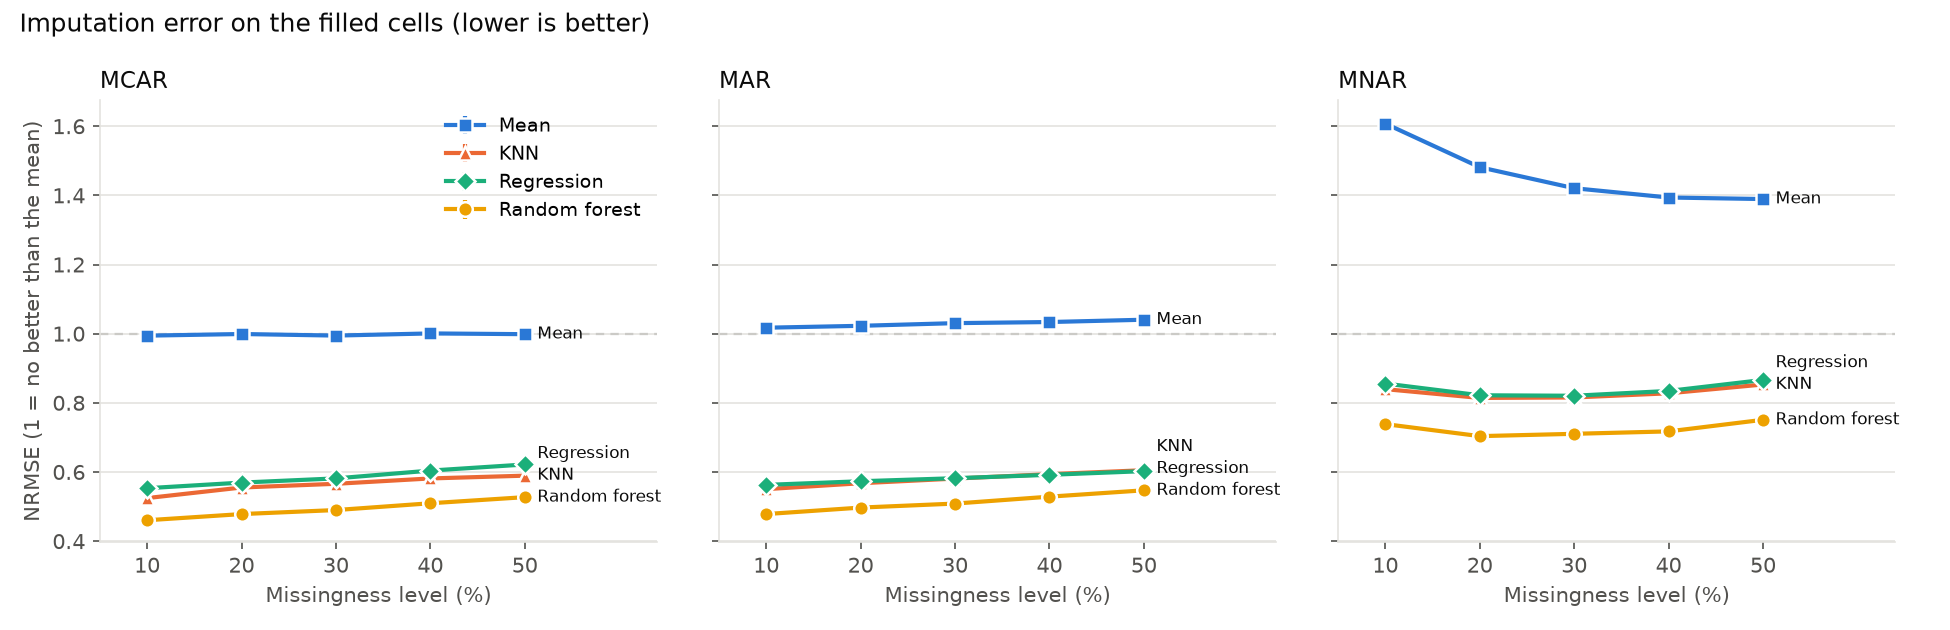

In [13]:
display(Image(filename=str(PROJECT_ROOT / "results/figures/fig_i1_nrmse_vs_level.png")))

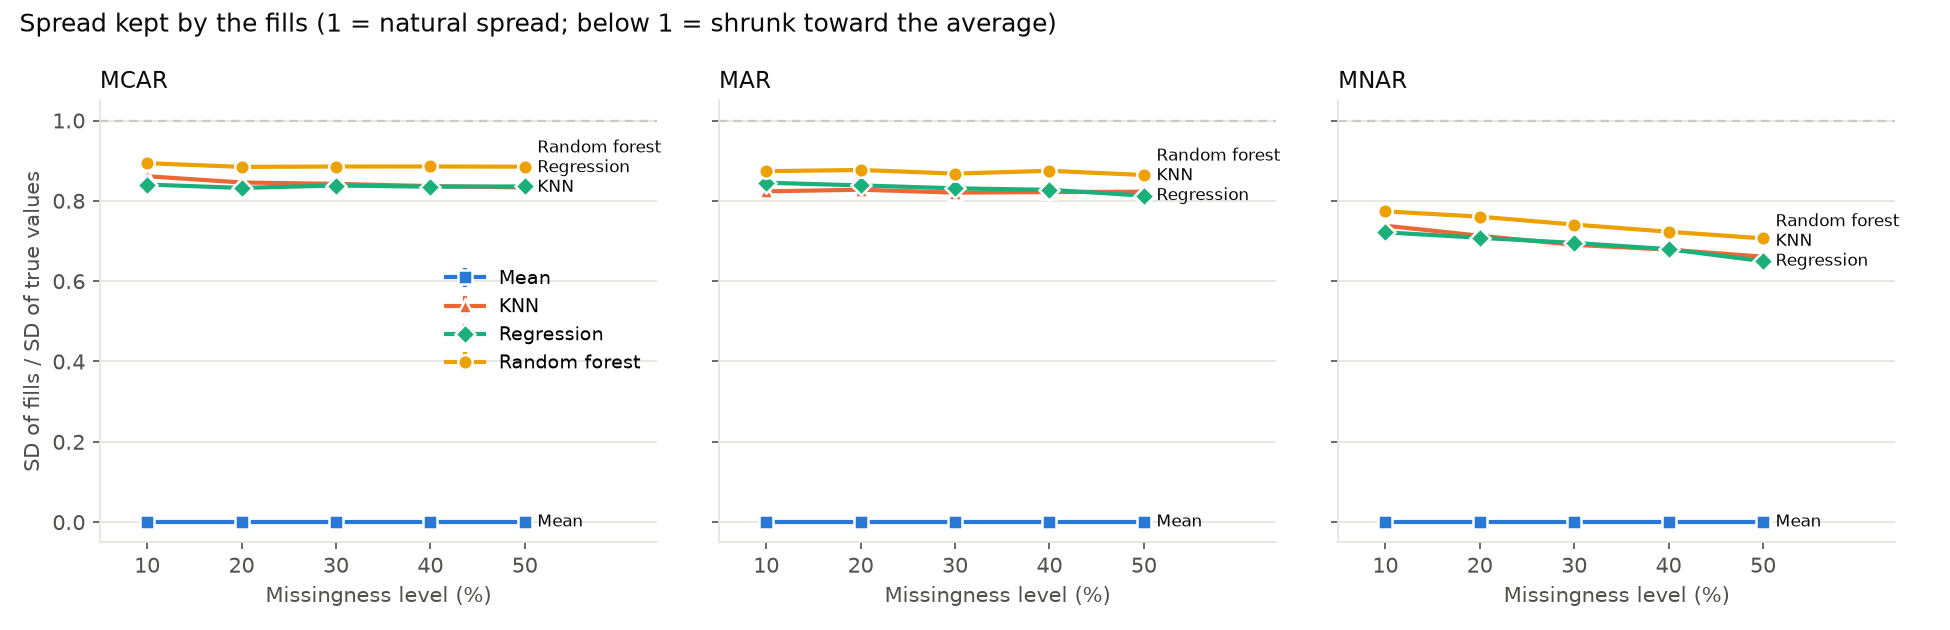

In [14]:
display(Image(filename=str(PROJECT_ROOT / "results/figures/fig_i2_sd_ratio_vs_level.png")))

## 6. Takeaways

1. **Random forest guessed most accurately** in every mechanism. KNN and regression were close behind, and mean imputation was the worst (the baseline).
2. **MNAR is hard for every method.** Under our MNAR design the large values are hidden, so all methods guess **too low**.
3. **Every method squeezes the spread** of the data (15–30% less than the true spread; mean imputation has no spread at all).
4. Point 3 is the link to our research question: **accurate guesses do not guarantee correct statistics**, because coefficients and standard errors depend on that spread. Member 3's analysis measures how much this matters.
5. Every result is **leak-free** (train rows only, price never used), **checked** and **reproducible** (fixed seed; a re-run gives identical files).